# Timing triplet: zero-lag $r$, maximum cross-correlation and phase-aligned correlation $P$ — 2026-10-20

A timing analogue of the $\{r, \rho, \mathrm{MI}\}$ case ([`r_rho_mi/`](../../r_rho_mi/README.md)). There, the pairs read monotone nonlinearity, non-monotone nonlinearity and linear-versus-general dependence. Here the three members differ only in how much realignment they allow before correlating a channel pair: none ($r$), one global delay (pyspi `xcorr_max_sig-True`), or any phase per frequency ($P$, bespoke). $\{r,\mathrm{xcorr}\}$ should separate synchronous from delayed recordings, $\{\mathrm{xcorr},P\}$ pure delay from dispersion, and $\{r,P\}$ any timing structure. All three are linear second-order statistics, so this is a linear-timing axis, complementary to the functional-form axis of $\{r,\rho,\mathrm{MI}\}$. The first rung is the introduction's Fig. 1 ([`delay_alias/`](../../delay_alias/README.md)).

Claims are labelled **verified** (derived and checked numerically here), **inferred** or **unverified**.

**Derivation (verified below).** Write the cross-spectrum of zero-mean stationary channels $j,k$ as $S_{jk}(f)=|S_{jk}(f)|e^{i\varphi_{jk}(f)}$ on $f\in(-\tfrac12,\tfrac12]$, and let $N_{jk}=\sqrt{\int S_{jj}\int S_{kk}}$. Real channels have odd $\varphi$, so the cross-covariance is $c_{jk}(h)=\int|S_{jk}|\cos(\varphi_{jk}+2\pi fh)\,df$. Then

$$r_{jk}=\frac{\int|S_{jk}|\cos\varphi_{jk}}{N_{jk}},\qquad \mathrm{xcorr}_{jk}=\max_h\frac{\int|S_{jk}|\cos(\varphi_{jk}+2\pi fh)}{N_{jk}},\qquad P_{jk}=\frac{\int|S_{jk}|}{N_{jk}}.$$

An all-pass filter $e^{i\theta(f)}$ on channel $k$ leaves $S_{kk}$ unchanged and replaces $\varphi$ by $\varphi-\theta$. Its zero-lag correlation $\int|S|\cos(\varphi-\theta)/N$ is at most $P$, with equality at $\theta=\varphi$. A delay is the all-pass with linear phase. Hence $r\le\mathrm{xcorr}\le P$ for every pair, nested over the alignment sets none, linear phase and any phase.
- **Pure delay gives $\mathrm{xcorr}=P$ exactly.** If $\varphi=-2\pi f\Delta$ wherever $|S|>0$, then $\mathrm{xcorr}=P$ at $h=\Delta$, for any spectrum.
- **$P$ is a power-weighted coherence.** $P=\int w|C|$ with $w=\sqrt{S_{jj}S_{kk}}/N$, and $\int w\le1$ (Cauchy–Schwarz), with equality iff the two spectra are proportional. A perfectly coherent pair with different spectral shapes has $P<1$, because an all-pass cannot reshape a spectrum.
- **One rung higher.** Allowing gain as well as phase, i.e. any linear filter of $k$, the supremum is the Wiener correlation $W=\sqrt{\int|S_{jk}|^2/S_{kk}\,/\int S_{jj}}\ge P$. It is asymmetric and not used further.
- **Correction to the brief.** pyspi `cohmag` is the unweighted mean over $f\in[0,\tfrac12]$ of the magnitude-squared coherence $|C|^2$, estimated with 5 tapers, not the mean of $|C|$. This was checked against `spectral_connectivity.Connectivity.coherence_magnitude`.

In [1]:
from pathlib import Path
import sys, json, time, logging, warnings
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for p in (ROOT, ROOT / 'src'):  # this checkout's mtsspi, not another editable install
    if str(p) not in sys.path: sys.path.insert(0, str(p))
warnings.filterwarnings('ignore'); logging.disable(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyspi, mtsspi
from mtsspi.generators import generate_band_delayed_mts, generate_delay_aliased_mts, band_delay_cross_spectrum
from research.cases.timing_triplet import timing_triplet as tt
assert Path(mtsspi.__file__).is_relative_to(ROOT / 'src')
tt.style(); pd.set_option('display.precision', 3)

PRM = dict(M=20, T=20_000, lag_range=15)  # generator defaults otherwise (section 2)
N_REP = 20
OUT = ROOT / 'results/cases/timing-triplet-261020'
OUT.mkdir(parents=True, exist_ok=True)
TRIP = [tt.pair_name(a, b) for a, b in tt.TRIPLET]
print(f"pyspi {pyspi.COMPUTATION_VERSION}; M={PRM['M']}, T={PRM['T']}, delay range {PRM['lag_range']}; "
      f"{N_REP} recordings per family; Welch segment {tt.NPERSEG}")

pyspi 3.0.0.r9; M=20, T=20000, delay range 15; 20 recordings per family; Welch segment 256


## 1. Numerical check of the ladder

The check uses 500 random pairs. Each has 1–5 spectral bumps per channel, a Gaussian-bump coherence profile and a phase made of a random integer delay plus a random sinusoidal (non-linear) term. Each pair reports violations of $r\le\mathrm{xcorr}\le P\le W\le1$ (population, $2^{14}$-point grid, lags $\pm2^{12}$), and the best zero-lag correlation reached by 200 random all-pass realignments, relative to $P$.

In [2]:
chk = tt.random_ladder_check(500, np.random.default_rng(0))
tol = 1e-12
pd.Series({'pairs': len(chk), 'r > xcorr': int((chk.r > chk.xcorr + tol).sum()), 'xcorr > P': int((chk.xcorr > chk.P + tol).sum()),
           'P > W': int((chk.P > chk.W + tol).sum()), 'W > 1': int((chk.W > 1 + tol).sum()),
           'random all-pass > P': int((chk.allpass_best > chk.P + tol).sum()), 'max all-pass / P': chk.allpass_best.div(chk.P).max(),
           'median xcorr / P': chk.xcorr.div(chk.P).median()}).to_frame('value')

,value
pairs,500.000
r > xcorr,0.000
xcorr > P,0.000
P > W,0.000
W > 1,0.000
random all-pass > P,0.000
max all-pass / P,1.000
median xcorr / P,0.719


## 2. Generator: three families with identical spectral magnitudes

`mtsspi.generators.generate_band_delayed_mts`, registry name `band_delayed_mts`. Each channel is a slow band (raised cosine on $|f|<0.08$) plus a fast band ($0.10<|f|<0.40$), unit variance each, plus white noise of variance 0.5. In each band, channel $j$ loads $l_{bj}\sim U(0.5,0.9)$ on a common drive, delayed by $\tau_{bj}$, and the rest is private. Positions are $\mathrm{round}(\mathrm{linspace}(0,15,M))$ in channel order.

| family | slow-band delays | fast-band delays | cross-spectral phase |
| --- | --- | --- | --- |
| synchronous | 0 | 0 | 0 |
| delayed | positions | positions | linear in $f$ |
| dispersive | positions | a fixed permutation of positions | linear per band, two slopes |

The bands do not overlap, so $|S_{jk}(f)|=l_{bj}l_{bk}s_b(f)$ in band $b$ and the auto-spectra do not depend on the delays. The three families therefore share every spectral magnitude: $P$ and the coherence magnitude have identical population matrices in all three, and only the phase differs. Loadings are drawn independently per band (`shared_loadings=False`), so different pairs are coherent in different bands; section 6 also uses one shared vector.

In [3]:
f = np.fft.rfftfreq(2**12)
POP = {fam: tt.population(PRM, fam) for fam in tt.FAMILIES}
Sabs = {fam: np.abs(band_delay_cross_spectrum(POP[fam]['internals'], f)) for fam in tt.FAMILIES}
rows = {}
for fam, pop in POP.items():
    d = pop['internals'].delays
    rows[fam] = {'max | |S| - |S_sync| |': np.abs(Sabs[fam] - Sabs['synchronous']).max(),
                 'mean r': tt.profile(pop['r']).mean(), 'mean xcorr': tt.profile(pop['xcorr']).mean(),
                 'mean P': tt.profile(pop['P']).mean(), 'max |xcorr - P|': np.abs(tt.profile(pop['xcorr'] - pop['P'])).max(),
                 'mean xcorr / P': (tt.profile(pop['xcorr']) / tt.profile(pop['P'])).mean(),
                 **{f'z {tt.pair_name(a, b)}': tt.z(pop[tt.SHORT[a]], pop[tt.SHORT[b]]) for a, b in tt.PAIRS}}
dl = POP['delayed']; lag_true = dl['internals'].delays[0][:, None] - dl['internals'].delays[0][None, :]
print('delayed family: argmax lag equals the delay difference for every pair:', bool((tt.profile(dl['lag'] - lag_true) == 0).all()))
pd.DataFrame(rows).T

delayed family: argmax lag equals the delay difference for every pair: True


,max | |S| - |S_sync| |,mean r,mean xcorr,mean P,max |xcorr - P|,mean xcorr / P,z r–xcorr,z xcorr–P,z r–P,z xcorr–cohmag,z cohmag–P
synchronous,0.000e+00,0.408,0.408,0.408,7.438e-15,1.000,1.000,1.000,1.000,0.894,0.894
delayed,5.329e-15,0.112,0.408,0.408,7.438e-15,1.000,0.352,1.000,0.352,0.894,0.894
dispersive,5.329e-15,0.111,0.325,0.408,2.203e-01,0.794,0.205,0.669,0.300,0.676,0.894


## 3. Estimating $P$

$\hat P$ uses Hann-window Welch cross-spectra with 50% overlap. On raw periodograms every pair can be phase-aligned perfectly, so $\hat P\approx\pi/4$ for independent white noise. Segment averaging restricts the realignment to phases that are smooth on the scale $1/L$ and leaves a positive bias at zero coherence. Longer segments $L$ resolve sharper phase structure but average fewer segments. The table uses five recordings per family, computed in numpy (the numpy maximum cross-correlation reproduces pyspi's `xcorr_max_sig-True` to $3\times10^{-15}$, section 7). It reports the null floor (mean $\hat P$ on independent white noise of the same size), the bias and RMSE of $\hat P$ against the population $P$, the fraction of pairs whose sample estimates keep $\hat r\le\widehat{\mathrm{xcorr}}\le\hat P$, and $z(\widehat{\mathrm{xcorr}},\hat P)$ by family.

In [4]:
noise = np.random.default_rng(1).standard_normal((PRM['T'], PRM['M']))
data = {fam: [generate_band_delayed_mts(family=fam, rng=tt.recording_rng(fam, rep, 99), **PRM) for rep in range(5)] for fam in tt.FAMILIES}
lagged = {fam: [tt.lagged_corr(d) for d in data[fam]] for fam in tt.FAMILIES}
rows = []
for L in (64, 128, 256, 512, 1024):
    row = {'segment L': L, 'segments': (PRM['T'] - L) // (L // 2) + 1, 'null floor': tt.profile(tt.phase_aligned_corr(noise, L)).mean()}
    for fam in tt.FAMILIES:
        Ph = [tt.phase_aligned_corr(d, L) for d in data[fam]]
        err = np.concatenate([tt.profile(p - POP[fam]['P']) for p in Ph])
        nested = np.concatenate([tt.profile((r0 <= xm) & (xm <= p)) for (r0, xm), p in zip(lagged[fam], Ph)])
        row |= {f'{fam[:4]} bias': err.mean(), f'{fam[:4]} rmse': np.sqrt((err**2).mean()), f'{fam[:4]} nested': nested.mean(),
                f'{fam[:4]} z(xc,P)': np.mean([tt.z(xm, p) for (_, xm), p in zip(lagged[fam], Ph)])}
    rows.append(row)
pd.DataFrame(rows).set_index('segment L').T

segment L,64,128,256,512,1024
segments,624.000,3.110e+02,155.000,77.000,38.000
null floor,0.037,5.173e-02,0.073,0.103,0.147
sync bias,-0.005,5.967e-04,0.006,0.012,0.022
sync rmse,0.012,8.755e-03,0.010,0.014,0.024
sync nested,0.356,6.053e-01,0.952,1.000,1.000
"sync z(xc,P)",0.991,9.975e-01,0.999,0.999,0.999
dela bias,-0.027,-4.256e-03,0.006,0.013,0.024
dela rmse,0.038,1.218e-02,0.011,0.016,0.026
dela nested,0.125,3.421e-01,0.922,1.000,1.000
"dela z(xc,P)",0.928,9.914e-01,0.999,0.999,0.999


$L=256$ is used throughout: 155 segments at $T=20\,000$, bias about $+0.02$, and $z(\widehat{\mathrm{xcorr}},\hat P)$ within 0.001 of $L=512$. The sample ladder is not an identity. Where $\mathrm{xcorr}=P$ in population (synchronous and delayed), the two estimators' different positive biases decide the order of a pair, so the nested fraction there mostly measures which bias is larger. Every $z$ below is a correlation across pairs, so a bias common to all pairs does not move it.

## 4. Which pair separates which family

Each family has 20 recordings with independent noise and shared structure (`structure_seed=0`). Each recording runs the pyspi subset in `spis/timing_triplet.yaml` (zero-lag Pearson as `cov_EmpiricalCovariance` on z-scored data, `xcorr_max_sig-True` over $\pm T/4$ lags, `cohmag`), plus $\hat P$.

In [5]:
t0 = time.time()
frame, mats = tt.measure(tt.band_makers(PRM), N_REP)
frame.to_csv(OUT / 'z_by_recording.csv', index=False)
print(f"{len(tt.FAMILIES) * N_REP} recordings in {time.time() - t0:.0f} s")
Z_POP = {(fam, tt.pair_name(a, b)): tt.z(POP[fam][tt.SHORT[a]], POP[fam][tt.SHORT[b]]) for fam in tt.FAMILIES for a, b in tt.PAIRS}
summ = frame.groupby(['pair', 'family']).z.agg(['mean', 'std']).unstack('family')
tab = pd.DataFrame({fam: [f"{summ.loc[p, ('mean', fam)]:.3f} ± {summ.loc[p, ('std', fam)]:.3f} ({Z_POP[(fam, p)]:.3f})" for p in summ.index]
                    for fam in tt.FAMILIES}, index=summ.index).loc[TRIP + [tt.pair_name(tt.XC, tt.CM), tt.pair_name(tt.CM, tt.P)]]
tab  # sample mean ± sd over recordings (population value)

60 recordings in 22 s


,synchronous,delayed,dispersive
pair,,,
r–xcorr,1.000 ± 0.000 (1.000),0.354 ± 0.020 (0.352),0.207 ± 0.014 (0.205)
xcorr–P,0.999 ± 0.000 (1.000),0.999 ± 0.000 (1.000),0.678 ± 0.009 (0.669)
r–P,0.999 ± 0.000 (1.000),0.365 ± 0.020 (0.352),0.295 ± 0.016 (0.300)
xcorr–cohmag,0.889 ± 0.008 (0.894),0.892 ± 0.008 (0.894),0.670 ± 0.012 (0.676)
cohmag–P,0.899 ± 0.006 (0.894),0.902 ± 0.007 (0.894),0.900 ± 0.005 (0.894)


In [6]:
rows = {}
for a, b in (('synchronous', 'delayed'), ('delayed', 'dispersive')):
    for p in TRIP:
        s = tt.separation(frame.query('family == @a and pair == @p').z, frame.query('family == @b and pair == @p').z)
        rows[(f'{a} vs {b}', p)] = s
sep = pd.DataFrame(rows).T[['A mean', 'B mean', 'AUC', 'p']]
iR, iX, iP = (tt.STATS.index(s) for s in (tt.R, tt.XC, tt.P))
nest = {fam: np.mean([tt.profile((m[iR] <= m[iX] + 1e-12) & (m[iX] <= m[iP] + 1e-12)).mean() for m in mats[fam]]) for fam in tt.FAMILIES}
# tolerance: pyspi's cov and the lag-0 cross-correlation agree only to ~1e-15
print('fraction of pairs with r <= xcorr <= P_hat (pyspi r, xcorr):', {k: round(float(v), 3) for k, v in nest.items()})
sep  # AUC = P(second family > first); 20 vs 20 recordings

fraction of pairs with r <= xcorr <= P_hat (pyspi r, xcorr): {'synchronous': 0.956, 'delayed': 0.9, 'dispersive': 0.993}


A mean  B mean   AUC          p
synchronous vs delayed r–xcorr   1.000   0.354  0.00  3.789e-08
                       xcorr–P   0.999   0.999  0.19  8.357e-04
                       r–P       0.999   0.365  0.00  6.796e-08
delayed vs dispersive  r–xcorr   0.354   0.207  0.00  6.796e-08
                       xcorr–P   0.999   0.678  0.00  6.796e-08
                       r–P       0.365   0.295  0.00  6.796e-08

## 5. The delay-aliasing families (Fig. 1) are pure delay

These are the same two families as [`delay_alias/`](../../delay_alias/README.md), with identical zero-lag correlation matrices: `lag_range` 0 versus 15, AR(1) $a=0.9$ and loadings $U(0.6,0.8)$. There are 10 recordings each. Every pair is a pure delay of one shared AR(1) spectrum, so $\mathrm{xcorr}=P$ in both families, and $|C_{jk}(f)|=|\Sigma^*_{jk}|$ does not depend on $f$.

In [7]:
DA = dict(M=20, T=20_000, max_lag_range=15, ar1_a=0.9, loading_low=0.6, loading_high=0.8, structure_seed=0)
alias_makers = {f'alias range {s}': (lambda rng, s=s: generate_delay_aliased_mts(lag_range=s, rng=rng, **DA)) for s in (0, 15)}
fa, ma = tt.measure(alias_makers, 10)
fa.groupby(['pair', 'family']).z.agg(['mean', 'std']).unstack('family').loc[TRIP + [tt.pair_name(tt.XC, tt.CM), tt.pair_name(tt.CM, tt.P)]]

mean                          std               
family       alias range 0 alias range 15 alias range 0 alias range 15
pair                                                                  
r–xcorr              1.000          0.450     2.024e-05      2.343e-02
xcorr–P              0.997          0.994     7.372e-04      9.277e-04
r–P                  0.997          0.476     7.326e-04      2.480e-02
xcorr–cohmag         0.968          0.972     4.222e-03      7.074e-03
cohmag–P             0.969          0.971     3.851e-03      5.902e-03

## 6. When is `cohmag` an acceptable proxy for $P$?

Both are blind to phase. They differ in three ways:
- **Weighting.** $P$ weights $|C(f)|$ by $\sqrt{S_{jj}S_{kk}}$. `cohmag` weights every frequency in $[0,\tfrac12]$ equally, including those that carry only noise.
- **Exponent.** `cohmag` averages $|C|^2$ rather than $|C|$.
- **Taper bias.** With 5 tapers, $E|\hat C|^2\approx|C|^2+(1-|C|^2)^2/5$, so noise-only frequencies add about 0.2 each.

Across pairs, `cohmag` is a monotone function of $P$ when the pair pattern of $|C_{jk}(f)|$ is the same at every frequency carrying power, $|C_{jk}(f)|=g_{jk}h(f)$. It is not when different bands couple different pairs. The comparison below uses independent loadings per band (the main families) against one shared loading vector, with 10 recordings per family for the shared variant.

In [8]:
PRM_S = {**PRM, 'shared_loadings': True}
fs, ms = tt.measure(tt.band_makers(PRM_S, suffix=' (shared)'), 10)
POP_S = {fam: tt.population(PRM_S, fam) for fam in tt.FAMILIES}
rows = []
for mode, fr, pops, sfx in (('independent per band', frame, POP, ''), ('shared', fs, POP_S, ' (shared)')):
    for fam in tt.FAMILIES:
        g = fr[fr.family == fam + sfx].groupby('pair').z.mean()
        pz = lambda a, b: tt.z(pops[fam][tt.SHORT[a]], pops[fam][tt.SHORT[b]])
        rows.append({'loadings': mode, 'family': fam,
                     'z cohmag-P': g[tt.pair_name(tt.CM, tt.P)], 'pop': pz(tt.CM, tt.P),
                     'z xcorr-P': g[tt.pair_name(tt.XC, tt.P)], 'pop ': pz(tt.XC, tt.P),
                     'z xcorr-cohmag': g[tt.pair_name(tt.XC, tt.CM)], 'pop  ': pz(tt.XC, tt.CM)})
for fam in fa.family.unique():
    g = fa[fa.family == fam].groupby('pair').z.mean()
    rows.append({'loadings': 'delay alias (one source)', 'family': fam, 'z cohmag-P': g[tt.pair_name(tt.CM, tt.P)],
                 'z xcorr-P': g[tt.pair_name(tt.XC, tt.P)], 'z xcorr-cohmag': g[tt.pair_name(tt.XC, tt.CM)]})
pd.DataFrame(rows).set_index(['loadings', 'family'])  # 'pop' columns: population value of the column to their left

z cohmag-P    pop  z xcorr-P   pop   \
loadings                 family                                                
independent per band     synchronous          0.899  0.894      0.999  1.000   
                         delayed              0.902  0.894      0.999  1.000   
                         dispersive           0.900  0.894      0.678  0.669   
shared                   synchronous          0.987  0.992      1.000  1.000   
                         delayed              0.987  0.992      0.999  1.000   
                         dispersive           0.987  0.992      0.744  0.733   
delay alias (one source) alias range 0        0.969    NaN      0.997    NaN   
                         alias range 15       0.971    NaN      0.994    NaN   

                                         z xcorr-cohmag  pop    
loadings                 family                                 
independent per band     synchronous              0.889  0.894  
                         delayed                  0.892  0.894  
                         dispersive               0.670  0.676  
shared                   synchronous              0.986  0.992  
                         delayed                  0.987  0.992  
                         dispersive               0.731  0.728  
delay alias (one source) alias range 0            0.968    NaN  
                         alias range 15           0.972    NaN

## 7. Limits

**Narrowband signals.** Within a narrow band around $f_0$, any smooth phase relation is approximately affine. A delay can then match the phase at $f_0$ modulo the period $1/f_0$ (the phase delay), so dispersion becomes indistinguishable from delay and $\mathrm{xcorr}\to P$. The population scan below makes both bands band-pass, $((0.05,0.05\kappa),(0.25,0.15\kappa))$, and shrinks the relative bandwidth $\kappa$. The lag window stays $\pm T/4$.

In [9]:
nb = tt.narrowband_scan(PRM, [1, 0.5, 0.25, 0.1, 0.05, 0.02])
display(nb.pivot(index='kappa', columns='family', values=['z_xcorr_P', 'mean_ratio']).sort_index(ascending=False))
# Residual at kappa = 0.02: integer lags cannot align a 4-sample fast carrier unless the band delays agree modulo 4.
pop = tt.population({**PRM, 'bands': ((0.05, 0.05 * 0.02), (0.25, 0.15 * 0.02))}, 'dispersive', 2**17)
ratio = pd.Series(tt.profile(pop['xcorr']) / tt.profile(pop['P']))
ratio.groupby(tt.profile(tt.band_mismatch(pop['internals'])).astype(int) % 4).agg(['size', 'mean', 'min']).rename_axis('mismatch mod 4')

z_xcorr_P            mean_ratio           
family   delayed dispersive    delayed dispersive
kappa                                            
1.00         1.0      0.574        1.0      0.684
0.50         1.0      0.724        1.0      0.790
0.25         1.0      0.938        1.0      0.904
0.10         1.0      0.975        1.0      0.953
0.05         1.0      0.974        1.0      0.961
0.02         1.0      0.973        1.0      0.963

,size,mean,min
mismatch mod 4,,,
0,44,1.000,0.999
1,55,0.976,0.969
2,50,0.907,0.873
3,41,0.976,0.965


Within one narrow band a smooth phase relation is a delay modulo the carrier period, so $z(\mathrm{xcorr},P)\approx1$ in narrowband data does not rule out dispersion, and the lag of the maximum is ambiguous modulo $1/f_0$. Across two separated narrow bands a single integer lag must match two carrier phases, which it can do only to the resolution of the lag grid.

**Second-order statistics.** $r$, $\mathrm{xcorr}$, $P$ and `cohmag` are functionals of the spectral matrix. A multivariate phase-randomised surrogate adds one random phase per frequency to every channel (Prichard and Theiler 1994). It preserves every sample auto- and cross-periodogram, so it preserves all three triplet members up to the circular-versus-linear lag difference and Welch segmentation. The table compares one recording per family with five surrogates, computed with the numpy estimators. The first line checks that numpy matches pyspi on that recording.

In [10]:
rows = []
for fam in tt.FAMILIES:
    x = generate_band_delayed_mts(family=fam, rng=tt.recording_rng(fam, 0), **PRM)
    orig = tt.numpy_triplet(x)
    if fam == 'synchronous':
        m0 = mats[fam][0]
        print('numpy vs pyspi max |diff|: r', np.abs(tt.profile(orig[tt.R] - m0[iR])).max(), ' xcorr', np.abs(tt.profile(orig[tt.XC] - m0[iX])).max())
    for s in range(5):
        sur = tt.numpy_triplet(tt.phase_randomise(x, np.random.default_rng(s)))
        for a, b in tt.TRIPLET:
            rows.append(dict(family=fam, pair=tt.pair_name(a, b), original=tt.z(orig[a], orig[b]), surrogate=tt.z(sur[a], sur[b])))
sur = pd.DataFrame(rows).groupby(['family', 'pair']).agg(original=('original', 'first'), surrogate_mean=('surrogate', 'mean'), surrogate_sd=('surrogate', 'std'))
sur

numpy vs pyspi max |diff|: r 8.659739592076221e-15  xcorr 3.4416913763379853e-15


original  surrogate_mean  surrogate_sd
family      pair                                           
delayed     r–P         0.346           0.345     1.636e-03
            r–xcorr     0.331           0.330     4.491e-04
            xcorr–P     0.999           0.998     1.221e-04
dispersive  r–P         0.326           0.327     1.217e-03
            r–xcorr     0.223           0.223     9.434e-05
            xcorr–P     0.670           0.674     2.178e-03
synchronous r–P         0.999           0.999     9.537e-05
            r–xcorr     1.000           1.000     1.110e-16
            xcorr–P     0.999           0.999     9.537e-05

## 8. Other structures

Loadings and the dispersive permutation are redrawn with structure seeds 1–5, using five recordings per family and seed. The table reports medians over recordings, with population values in parentheses.

In [11]:
rows = []
for seed in range(1, 6):
    p = {**PRM, 'structure_seed': seed}
    fr, _ = tt.measure(tt.band_makers(p), 5, seed=seed)
    pops = {fam: tt.population(p, fam) for fam in tt.FAMILIES}
    for fam in tt.FAMILIES:
        g = fr[fr.family == fam].groupby('pair').z.median()
        rows.append({'seed': seed, 'family': fam, **{q: f"{g[q]:.2f} ({tt.z(pops[fam][tt.SHORT[a]], pops[fam][tt.SHORT[b]]):.2f})"
                                                     for q, (a, b) in zip(TRIP, tt.TRIPLET)}})
pd.DataFrame(rows).pivot(index='seed', columns='family')

r–xcorr                                xcorr–P               \
family      delayed   dispersive  synchronous      delayed   dispersive   
seed                                                                      
1       0.16 (0.16)  0.17 (0.17)  1.00 (1.00)  1.00 (1.00)  0.70 (0.70)   
2       0.14 (0.13)  0.11 (0.11)  1.00 (1.00)  1.00 (1.00)  0.52 (0.49)   
3       0.16 (0.15)  0.27 (0.28)  1.00 (1.00)  1.00 (1.00)  0.58 (0.57)   
4       0.20 (0.20)  0.25 (0.26)  1.00 (1.00)  1.00 (1.00)  0.45 (0.42)   
5       0.07 (0.07)  0.27 (0.26)  1.00 (1.00)  1.00 (1.00)  0.50 (0.48)   

                             r–P                            
family  synchronous      delayed   dispersive  synchronous  
seed                                                        
1       1.00 (1.00)  0.17 (0.16)  0.19 (0.19)  1.00 (1.00)  
2       1.00 (1.00)  0.15 (0.13)  0.10 (0.09)  1.00 (1.00)  
3       1.00 (1.00)  0.17 (0.15)  0.18 (0.18)  1.00 (1.00)  
4       1.00 (1.00)  0.22 (0.20)  0.14 (0.14)  1.00 (1.00)  
5       1.00 (1.00)  0.09 (0.07)  0.13 (0.14)  1.00 (1.00)

## 9. Figure

The main panel shows replicate 0 of the delayed and dispersive families. The x-axis is each channel pair's $\hat P$ and the y-axis its maximum cross-correlation; dispersive pairs are coloured by the difference between their slow-band and fast-band delays. The inset shows $z$ for every recording (dots, coloured by family) and the population value (open markers joined by lines) for the three triplet pairs.

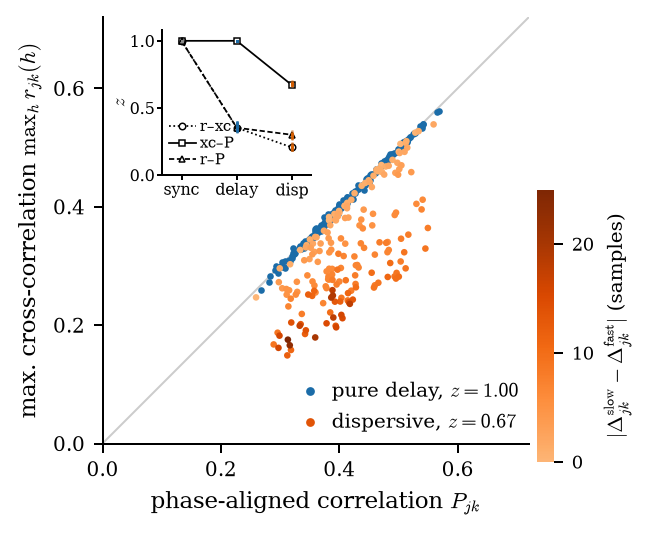

saved ['summary.json', 'timing_triplet.pdf', 'timing_triplet.png', 'timing_triplet.svg', 'z_by_recording.csv']


In [12]:
fig = tt.plot_fig(mats, frame, PRM, Z_POP)
tt.save(fig, OUT, 'timing_triplet'); plt.show()
summary = dict(params=PRM, generator_defaults='band_delayed_mts defaults: bands ((0,0.08),(0.25,0.15)), band_var (1,1), noise_var 0.5, loadings U(0.5,0.9)',
               n_rep=N_REP, nperseg=tt.NPERSEG, pyspi=pyspi.COMPUTATION_VERSION,
               z_mean=frame.groupby(['family', 'pair']).z.mean().unstack().to_dict(),
               z_sd=frame.groupby(['family', 'pair']).z.std().unstack().to_dict(),
               z_population={f'{k[0]}|{k[1]}': v for k, v in Z_POP.items()},
               separation=sep.reset_index().astype({'level_0': str, 'level_1': str}).to_dict('records'),
               nested_fraction=nest, alias=fa.groupby(['family', 'pair']).z.mean().unstack().to_dict(),
               shared=fs.groupby(['family', 'pair']).z.mean().unstack().to_dict(),
               narrowband=nb.to_dict('records'), ladder_check=dict(pairs=len(chk), max_allpass_over_P=float(chk.allpass_best.div(chk.P).max())))
(OUT / 'summary.json').write_text(json.dumps(summary, indent=1, default=float))
print('saved', sorted(p.name for p in OUT.iterdir()))

## Summary

Numbers are from the run above: $M=20$, $T=20\,000$, delay range 15 samples, 20 recordings per family, Welch $L=256$.

- **Ladder (verified).** $r\le\mathrm{xcorr}\le P\le W\le1$ held for 500 random population pairs, and no random all-pass realignment exceeded $P$. Pure delay gives $\mathrm{xcorr}=P$ to $10^{-14}$, with the peak at the true delay difference (sections 1–2).
- **$\{r,\mathrm{xcorr}\}$ separates synchronous from lagged.** $z$ is 1.000, 0.354 ± 0.020 and 0.207 ± 0.014 for synchronous, delayed and dispersive. It does not order delayed against dispersive: dispersive is lower at structure seeds 0 and 2 and higher at seeds 1, 3, 4 and 5.
- **$\{\mathrm{xcorr},P\}$ separates pure delay from dispersion.** $z$ is 0.9988 synchronous, 0.9985 delayed (population 1 for both) and 0.678 ± 0.009 dispersive (population 0.669). Across seeds 1–5 it is 0.45–0.70 for dispersive and 1.00 for delayed. The 0.0003 synchronous–delayed gap (AUC 0.19) is a Welch segmentation effect.
- **$\{r,P\}$ responds to any timing structure:** 0.999 / 0.365 / 0.295. Every sample mean lies within 0.013 of its population value.
- **`cohmag` is mean magnitude-squared coherence (verified), not mean $|C|$.**
  - With independent band loadings, $z(\mathrm{cohmag},P)=0.90$ in every family. Under pure delay $z(\mathrm{xcorr},\mathrm{cohmag})=0.89$, while $z(\mathrm{xcorr},P)=0.999$, so `cohmag` would read pure delay as dispersion.
  - With loadings shared across bands, $z(\mathrm{cohmag},P)=0.987$; with one source (delay-alias families) it is 0.97.
  - The proxy is acceptable when the across-pair coherence pattern is the same at every frequency carrying power (inferred condition).
- **Narrowband (verified in population).** The dispersive $z(\mathrm{xcorr},P)$ rises from 0.57 to 0.97 as the bands shrink to 2% of their width. The residual is the integer-lag grid at a 4-sample carrier: pairs whose band delays agree modulo 4 reach $\mathrm{xcorr}/P=1.000$.
- **Second order (verified).** Multivariate phase-randomised surrogates preserve every triplet $z$ to within 0.004. Findings on this axis are linear lag/spectral organisation.
- **Sample ladder.** With pyspi's $r$ and xcorr, $\hat r\le\widehat{\mathrm{xcorr}}\le\hat P$ held for 96% / 90% / 99% of pairs. Where $\mathrm{xcorr}=P$ in population, the estimators' different biases break the tie.
- **Unverified.** One targeted search found no named precedent for $P$; this is not a priority review.